# Clustering: K-Means with Model Selection, and Agglomerative Clustering from Scratch
  A. K-means on a 2-D dataset (2,360 points); number of clusters chosen with the elbow method,
     cross-checked with the silhouette score
  B. Bottom-up hierarchical clustering implemented from scratch (single, average and complete
     linkage) on a 1-D dataset, validated against SciPy

Run from this folder:  python clustering.py   (figures are written to ./figures)

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

HERE = os.path.dirname(os.path.abspath(__file__)) if "__file__" in globals() else "."
DATA = os.path.join(HERE, "data")
FIG = os.path.join(HERE, "figures")
os.makedirs(FIG, exist_ok=True)

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#8a5cd1", "#d4a017", "#d6456b", "#4aa3a2", "#6b6b6b"]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "font.size": 10})

## A. K-means and choosing k

k  WCSS      drop vs k-1   silhouette
 1    4720.0      -          -  
 2    2755.8     41.6%      0.416
 3    1506.6     45.3%      0.495
 4     858.6     43.0%      0.571
 5     611.9     28.7%      0.580
 6     459.0     25.0%      0.562
 7     365.0     20.5%      0.561
 8     332.4      8.9%      0.539
 9     301.6      9.2%      0.501
10     277.0      8.2%      0.495
11     254.4      8.2%      0.500
12     233.8      8.1%      0.503
13     218.8      6.4%      0.499
14     204.7      6.5%      0.484
15     195.4      4.5%      0.449
cluster 1: 490 points, centre [ 4.578 -4.593]
cluster 2: 464 points, centre [-2.648  2.474]
cluster 3: 740 points, centre [6.164 4.032]
cluster 4: 274 points, centre [-6.89  7.06]
cluster 5: 392 points, centre [-5.135 -5.191]
final WCSS (standardised units): 611.861


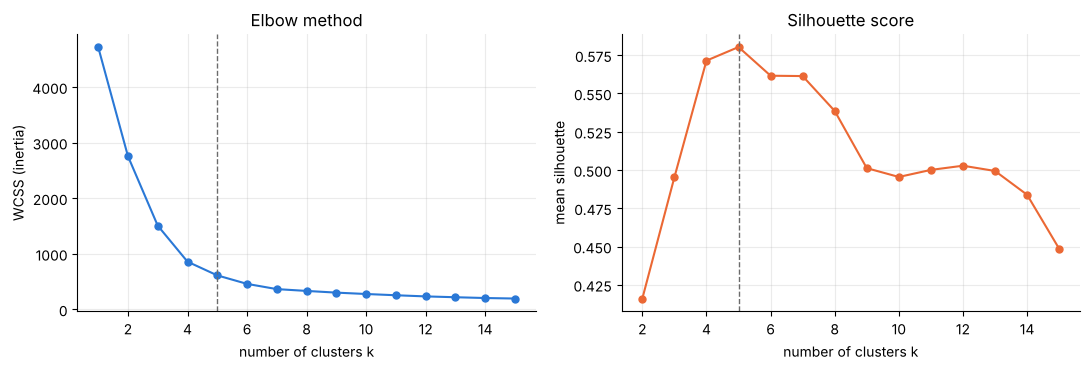

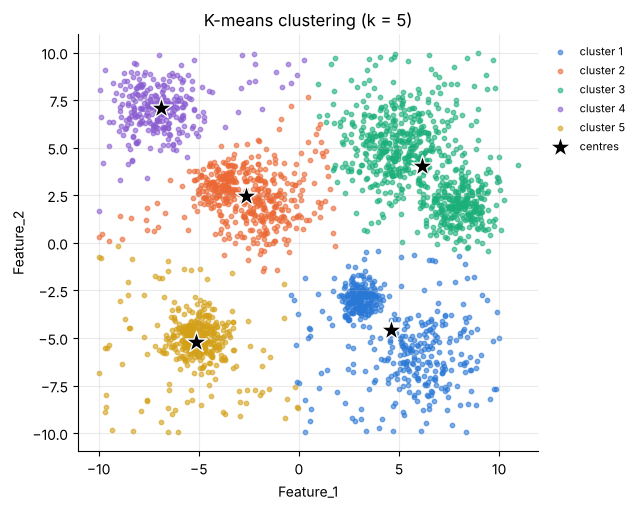

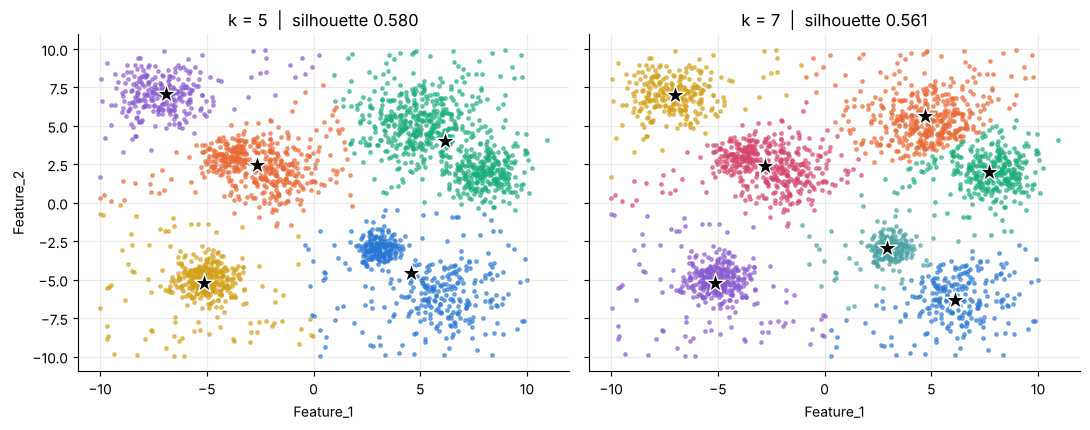

In [2]:
df = pd.read_csv(os.path.join(DATA, "kmeans_2d.csv"))
X = df.values
sc = StandardScaler()
Xs = sc.fit_transform(X)

ks = range(1, 16)
inertia, sil = [], {}
for k in ks:
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=0).fit(Xs)
    inertia.append(km.inertia_)
    if k >= 2:
        sil[k] = silhouette_score(Xs, km.labels_)

# relative drop in WCSS when going from k-1 to k
drops = {k: (inertia[k - 2] - inertia[k - 1]) / inertia[k - 2] for k in range(2, 16)}
print("k  WCSS      drop vs k-1   silhouette")
for k in ks:
    d = f"{drops[k] * 100:6.1f}%" if k in drops else "   -  "
    s = f"{sil[k]:.3f}" if k in sil else "  -  "
    print(f"{k:>2} {inertia[k - 1]:9.1f}   {d}      {s}")

K_BEST = 5   # elbow of the WCSS curve (see report for the discussion with the silhouette score)
km = KMeans(n_clusters=K_BEST, init="k-means++", n_init=10, random_state=0).fit(Xs)
labels = km.labels_
centres = sc.inverse_transform(km.cluster_centers_)
for i in range(K_BEST):
    print(f"cluster {i + 1}: {np.sum(labels == i)} points, centre {centres[i].round(3)}")
print("final WCSS (standardised units):", round(km.inertia_, 3))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(list(ks), inertia, "o-", color=PALETTE[0], ms=5)
axes[0].axvline(K_BEST, color="#6b6b6b", ls="--", lw=1)
axes[0].set(xlabel="number of clusters k", ylabel="WCSS (inertia)", title="Elbow method")
axes[1].plot(list(sil), list(sil.values()), "o-", color=PALETTE[1], ms=5)
axes[1].axvline(K_BEST, color="#6b6b6b", ls="--", lw=1)
axes[1].set(xlabel="number of clusters k", ylabel="mean silhouette", title="Silhouette score")
plt.tight_layout()
plt.savefig(os.path.join(FIG, "elbow_silhouette.png"), dpi=160)
plt.show()

fig, ax = plt.subplots(figsize=(6.5, 5.2))
for i in range(K_BEST):
    pts = X[labels == i]
    ax.scatter(pts[:, 0], pts[:, 1], s=10, alpha=0.6, color=PALETTE[i], label=f"cluster {i + 1}")
ax.scatter(centres[:, 0], centres[:, 1], marker="*", s=260, c="black", edgecolors="white", zorder=5,
           label="centres")
ax.set(xlabel=df.columns[0], ylabel=df.columns[1], title=f"K-means clustering (k = {K_BEST})")
ax.legend(frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(1.0, 1.0))
plt.tight_layout()
plt.savefig(os.path.join(FIG, "kmeans_clusters.png"), dpi=160)
plt.show()

# The WCSS drops show a second knee at k = 7 (25% and 20% drops, then 9%), so compare k = 5 and k = 7
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
for ax, k in zip(axes, [5, 7]):
    m = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=0).fit(Xs)
    c = sc.inverse_transform(m.cluster_centers_)
    for i in range(k):
        ax.scatter(X[m.labels_ == i, 0], X[m.labels_ == i, 1], s=6, alpha=0.6, color=PALETTE[i])
    ax.scatter(c[:, 0], c[:, 1], marker="*", s=220, c="black", edgecolors="white", zorder=5)
    ax.set(title=f"k = {k}  |  silhouette {sil[k]:.3f}", xlabel=df.columns[0])
axes[0].set_ylabel(df.columns[1])
plt.tight_layout()
plt.savefig(os.path.join(FIG, "kmeans_k5_vs_k7.png"), dpi=160)
plt.show()

## B. Agglomerative clustering from scratch

Single linkage    final merge height   10.696 | merge heights match SciPy: True
Average linkage   final merge height   53.829 | merge heights match SciPy: True
Complete linkage  final merge height   94.933 | merge heights match SciPy: True


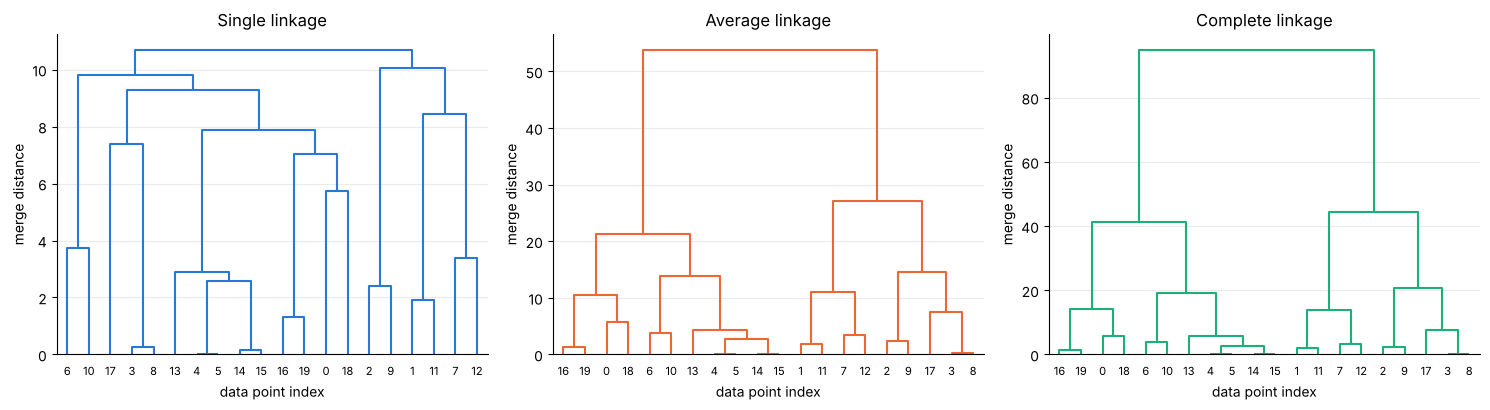


sorted 1-D values: [ 2.06  5.81 15.6  15.6  18.18 18.34 21.23 29.12 30.42 37.45 43.19 52.48
 59.87 60.11 70.81 73.2  83.24 86.62 95.07 96.99]


In [3]:
d2 = pd.read_csv(os.path.join(DATA, "hierarchical_1d.csv"))
P = d2.values.reshape(-1, 1) if d2.shape[1] == 1 else d2.values


def dist(a, b):
    return float(np.sqrt(np.sum((a - b) ** 2)))


def d_min(A, B, data):      # single linkage
    return min(dist(data[i], data[j]) for i in A for j in B)


def d_avg(A, B, data):      # average linkage
    return float(np.mean([dist(data[i], data[j]) for i in A for j in B]))


def d_max(A, B, data):      # complete linkage
    return max(dist(data[i], data[j]) for i in A for j in B)


def agglomerative(data, link):
    """Repeatedly merge the two closest clusters; returns a SciPy-style linkage matrix."""
    clusters = {i: [i] for i in range(len(data))}
    next_id, Z = len(data), []
    while len(clusters) > 1:
        ids = list(clusters)
        best, pair = np.inf, None
        for p in range(len(ids)):
            for q in range(p + 1, len(ids)):
                d = link(clusters[ids[p]], clusters[ids[q]], data)
                if d < best:
                    best, pair = d, (ids[p], ids[q])
        a, b = pair
        merged = clusters.pop(a) + clusters.pop(b)
        Z.append([a, b, best, len(merged)])
        clusters[next_id] = merged
        next_id += 1
    return np.array(Z)


methods = [("single", d_min, "Single linkage"), ("average", d_avg, "Average linkage"),
           ("complete", d_max, "Complete linkage")]
Zs = {}
for key, fn, title in methods:
    Zs[key] = agglomerative(P, fn)
    ref = linkage(P, method=key, metric="euclidean")
    same = np.allclose(np.sort(Zs[key][:, 2]), np.sort(ref[:, 2]))
    print(f"{title:<17} final merge height {Zs[key][-1, 2]:8.3f} | merge heights match SciPy: {same}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (key, _, title), col in zip(axes, methods, PALETTE[:3]):
    dendrogram(Zs[key], ax=ax, link_color_func=lambda k, c=col: c, leaf_font_size=8)
    ax.set(title=title, xlabel="data point index", ylabel="merge distance")
    ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.savefig(os.path.join(FIG, "dendrograms.png"), dpi=160)
plt.show()

print("\nsorted 1-D values:", np.round(np.sort(P.ravel()), 2))